# P22 experiments and results
This notebook runs top to bottom. It uses saved results when available. Set RETRAIN=True to regenerate every experiment; if outputs are absent, it runs the full pipeline automatically.

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

In [2]:
import subprocess
RETRAIN = False
if RETRAIN or not (ROOT/'results/summary.csv').exists():
    subprocess.run([sys.executable,'run_project.py'],check=True)

In [3]:
import pandas as pd
pd.read_csv('results/summary.csv')

,model,mae_mean,mae_std,rmse_mean,rmse_std,train_seconds_mean,runs
0,Persistence,2.469152,0.000000,3.237355,0.000000,0.000000,1
1,Ridge,2.355639,0.000000,2.996876,0.000000,2.408107,1
2,GRU,2.185039,0.005415,2.815054,0.003849,40.393315,3
3,GRU_calendar,2.091469,0.012104,2.703969,0.013772,47.962629,3


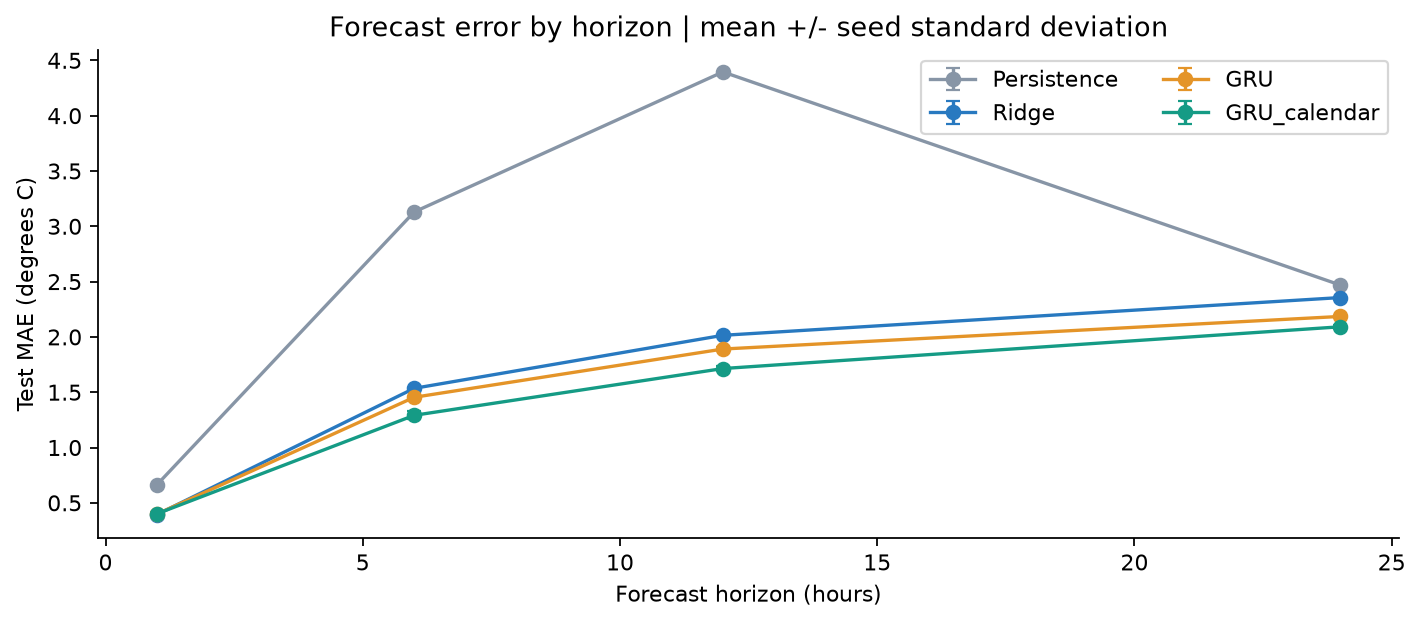

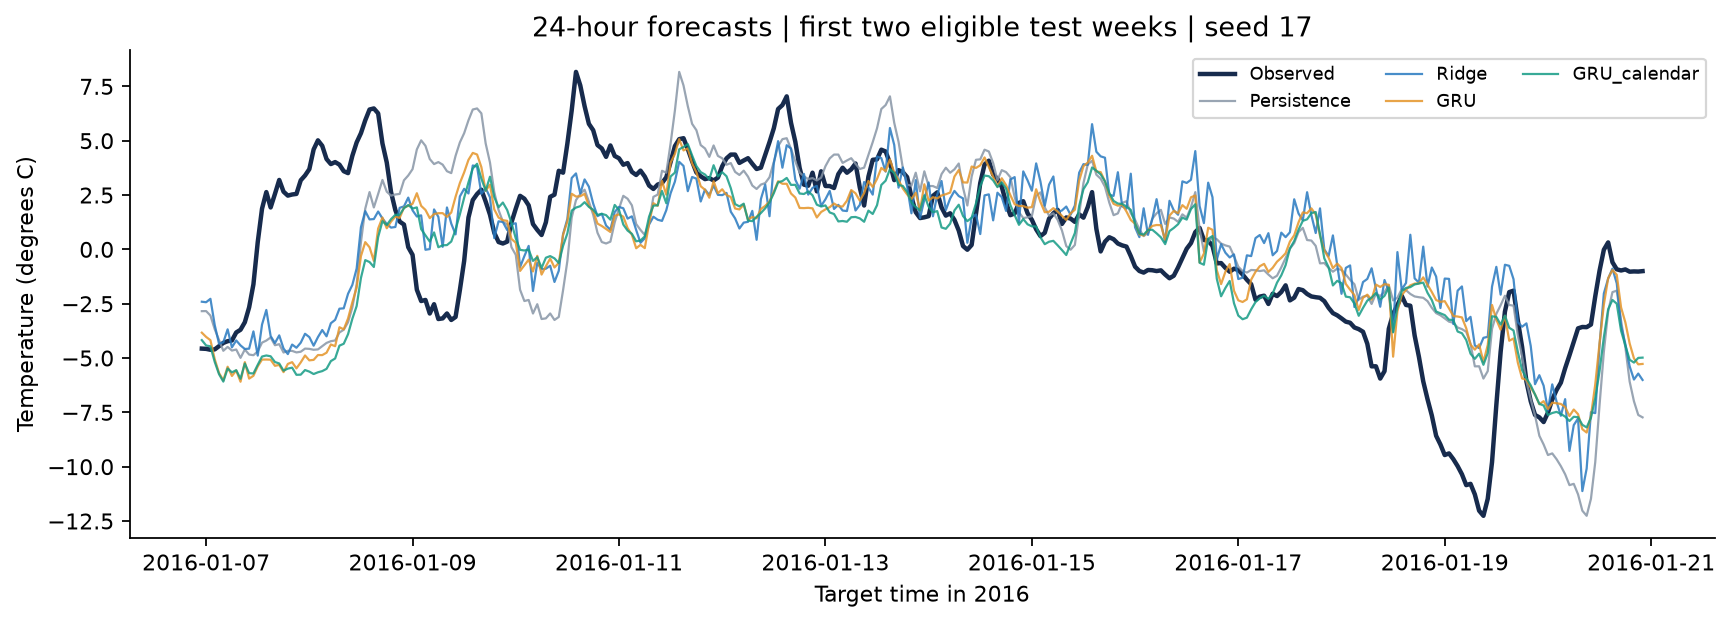

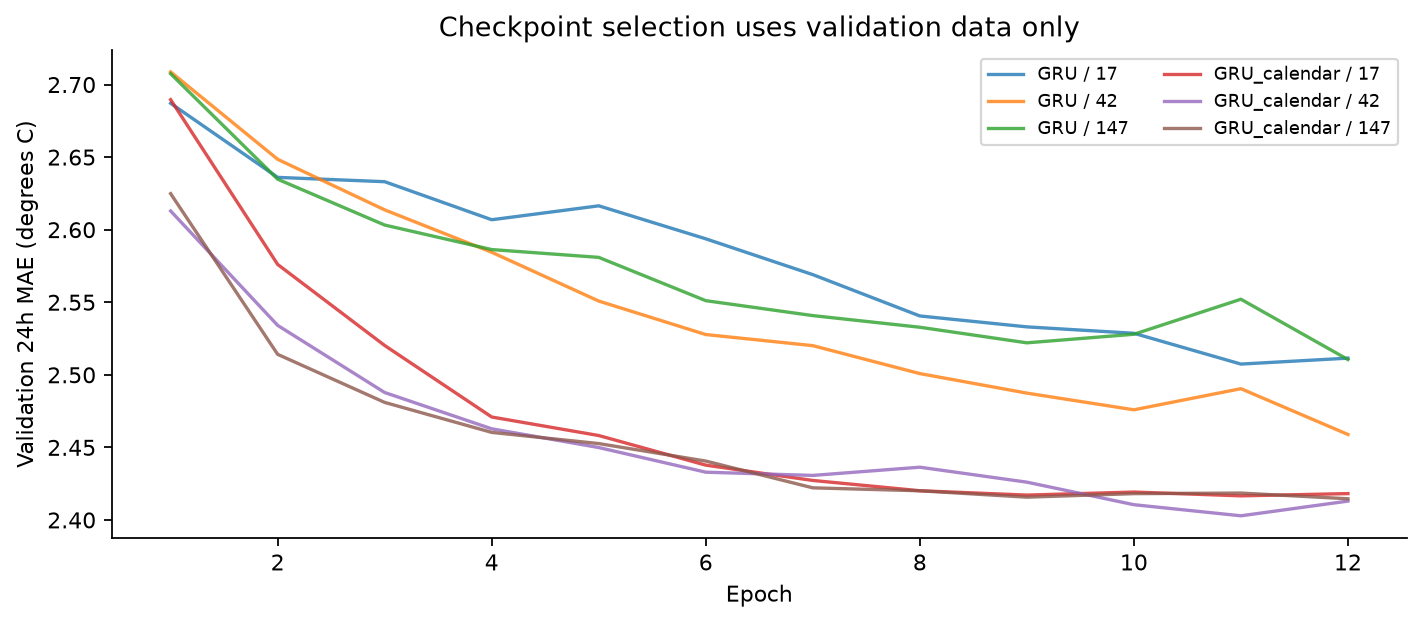

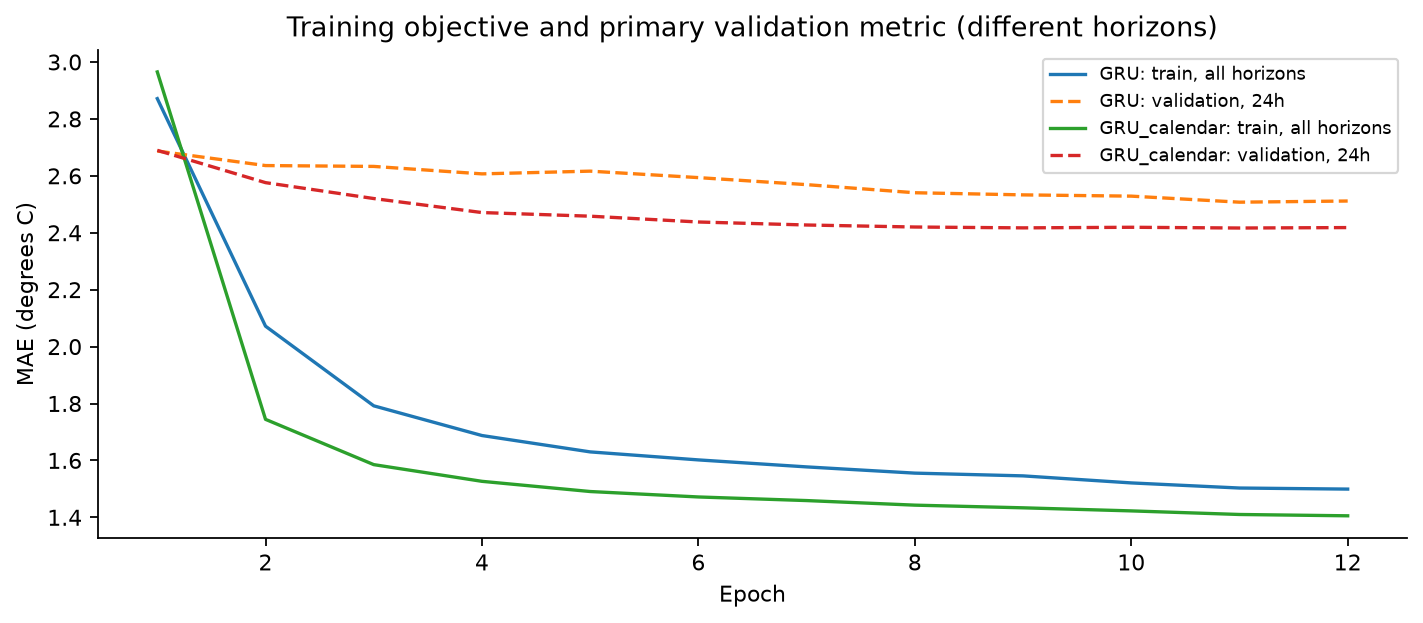

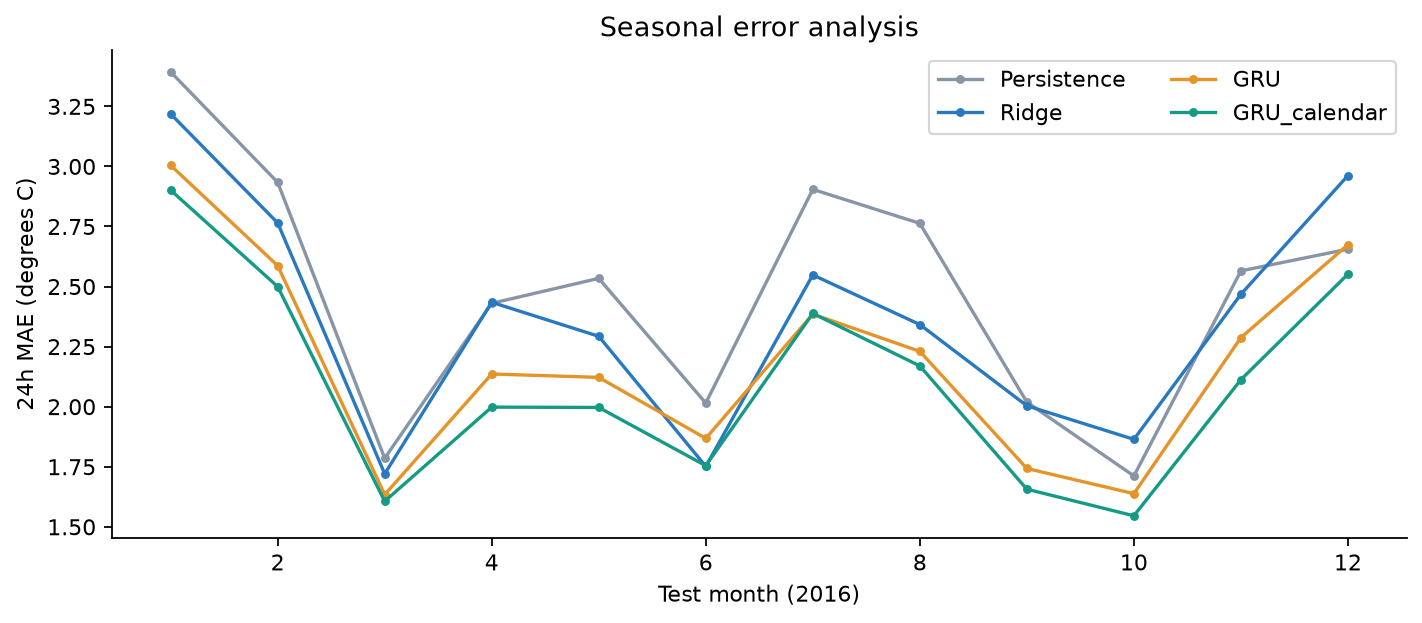

In [4]:
from IPython.display import display, Image
for name in ['horizon_mae','two_test_weeks','learning_curves','training_curves','monthly_errors']:
    display(Image(filename=f'results/figures/{name}.png'))

In [5]:
pd.read_csv('results/largest_errors.csv')

,target_time,actual,Persistence,Ridge,GRU,GRU_calendar,absolute_error_calendar
0,2016-05-23 19:00:00,13.185000,28.028334,24.201845,23.521328,24.627867,11.442866
1,2016-01-23 11:00:00,3.188333,-10.198334,-6.971081,-6.530654,-7.587877,10.776211
2,2016-01-08 02:00:00,5.016667,-4.603333,-4.038288,-4.862117,-5.656013,10.672680
3,2016-01-08 03:00:00,4.765000,-4.453333,-3.711469,-4.865164,-5.601838,10.366838
4,2016-01-08 01:00:00,4.598333,-4.620000,-4.432068,-5.084804,-5.737359,10.335692
5,2016-01-23 12:00:00,3.940000,-8.006667,-4.728988,-4.438289,-6.357562,10.297562
6,2016-05-23 18:00:00,14.728333,29.076666,24.697087,23.903255,24.940372,10.212039
7,2016-05-23 20:00:00,12.876667,25.765000,23.099015,22.252644,22.913565,10.036898
8,2016-04-23 14:00:00,4.390000,11.838333,12.064021,13.252844,14.297661,9.907661
9,2016-04-23 15:00:00,4.730000,12.555000,12.369955,13.473774,14.635468,9.905468


In [6]:
subprocess.run([sys.executable,'-m','unittest','discover','-s','tests','-v'],check=True)

CompletedProcess(args=['D:\\XboxGames\\sanjay\\Sanjhay_EC417_P22_Jena_Climate\\Term Project\\.venv\\Scripts\\python.exe', '-m', 'unittest', 'discover', '-s', 'tests', '-v'], returncode=0)

## Discussion
Use the measured MAE change to state whether calendar features helped. Seed spread measures optimization variability only. Review the largest errors and limitations before the viva. AI assistance is disclosed in README.md.